In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Temperature prediction

## Create time series data for tavg

In [2]:
clean_df = pd.read_csv("../processed/final_data.csv")
clean_df = clean_df.set_index("date")
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


Text(0.5, 0, 'Date')

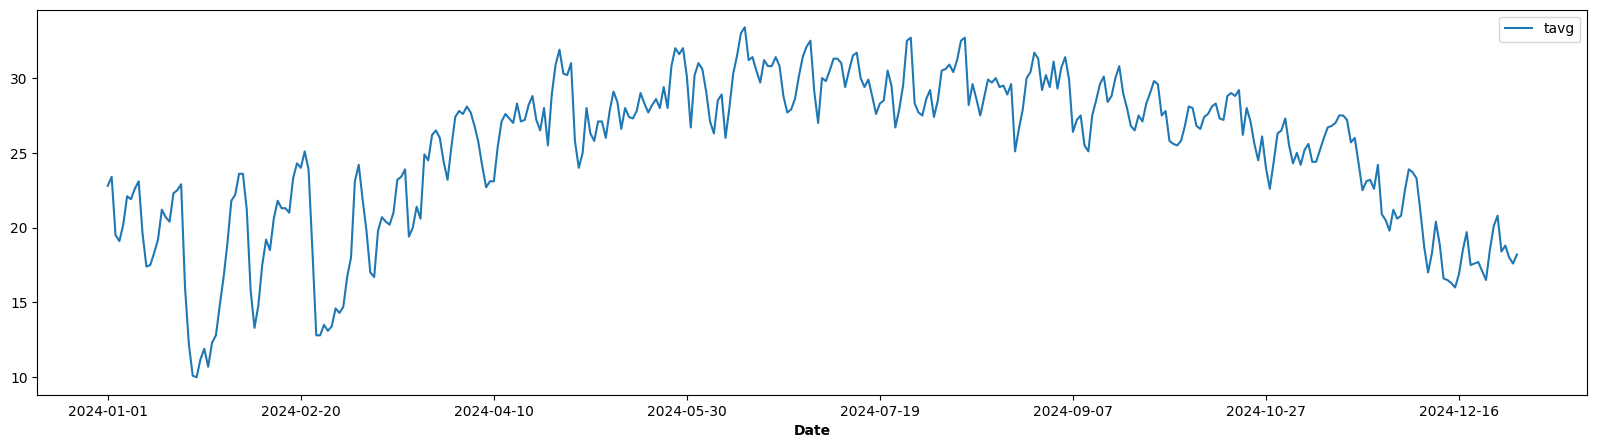

In [3]:
tavg_data = clean_df[clean_df["is_deleted"] == False][["tavg"]].reset_index()
ax = tavg_data.plot.line(x="date", y="tavg", figsize=(20,5))
ax.set_xlabel("Date", fontweight="bold")

In [4]:
def create_ts_data(data, window_size=5):
    ts_data = data.copy()
    
    for i in range(window_size):
        shift_amount = window_size - i
        ts_data[f"tavg_{i + 1}"] = ts_data["tavg"].shift(shift_amount)

    ts_data["target"] = ts_data["tavg"]
    ts_data = ts_data.drop(columns=["tavg"])
    ts_data = ts_data.dropna()
    return ts_data 

In [5]:
tavg_data = create_ts_data(tavg_data)
tavg_data 

,date,tavg_1,tavg_2,tavg_3,tavg_4,tavg_5,target
5,2024-01-06,22.8,23.4,19.5,19.1,20.2,22.1
6,2024-01-07,23.4,19.5,19.1,20.2,22.1,21.9
7,2024-01-08,19.5,19.1,20.2,22.1,21.9,22.6
8,2024-01-09,19.1,20.2,22.1,21.9,22.6,23.1
9,2024-01-10,20.2,22.1,21.9,22.6,23.1,19.6
...,...,...,...,...,...,...,...
361,2024-12-27,17.1,16.5,18.5,20.1,20.8,18.4
362,2024-12-28,16.5,18.5,20.1,20.8,18.4,18.8
363,2024-12-29,18.5,20.1,20.8,18.4,18.8,18.0
364,2024-12-30,20.1,20.8,18.4,18.8,18.0,17.6


## Train test split

In [6]:
X = tavg_data.drop(columns=["date","target"])
y = tavg_data["target"]

In [7]:
train_size = int(len(tavg_data) * 0.8)

X_train = X[:train_size]
y_train = y[:train_size]
X_test = X[train_size:]
y_test = y[train_size:]

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((288, 5), (288,), (73, 5), (73,))

## Grid search

In [8]:
model = RandomForestRegressor(random_state=42)

In [9]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "criterion": ["squared_error", "absolute_error", "poisson"],
    "max_depth": [None, 10, 20, 30],
    "max_features": ['sqrt', 'log2']
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid, 
                           cv=5, verbose=2, scoring='r2')

grid_search.fit(X_train, y_train)
print(f"best params: {grid_search.best_params_}")
print(f"best r2: {grid_search.best_score_}")

Fitting 5 folds for each of 72 candidates, totalling 360 fits
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=100; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=100; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=100; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=100; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=100; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=200; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=200; total time=   0.0s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=200; total time=   0.1s
[CV] END criterion=squared_error, max_depth=None, max_features=sqrt, n_estimators=200; tot

# Train step

In [10]:
model = RandomForestRegressor(criterion= "squared_error", 
                              max_depth= 10, 
                              max_features= "sqrt", 
                              n_estimators= 200,
                              random_state=0)
model.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [11]:
y_pred = model.predict(X_test)

In [12]:
print(f"R2: {r2_score(y_test, y_pred)}")
print(f"MSE: {mean_squared_error(y_test, y_pred)}")
print(f"MAE: {mean_absolute_error(y_test, y_pred)}")

R2: 0.7740417783738349
MSE: 3.053762822891263
MAE: 1.3994017035801434


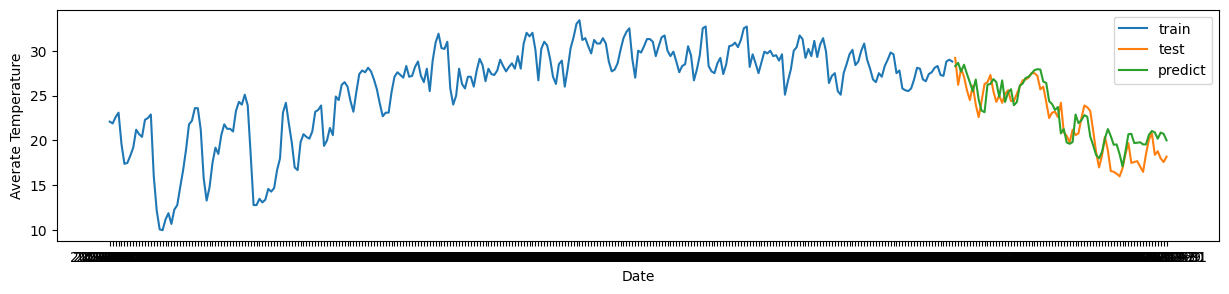

In [13]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,3))
ax.plot(tavg_data["date"][:train_size], tavg_data["target"][:train_size], label="train")
ax.plot(tavg_data["date"][train_size:], tavg_data["target"][train_size:], label="test")
ax.plot(tavg_data["date"][train_size:], y_pred, label="predict")
ax.set_xlabel("Date")
ax.set_ylabel("Averate Temperature")
plt.legend()
plt.show()

In [14]:
feature_names = X_train.columns.tolist()

days_predict = 14
future_pred = []
future_dates = pd.date_range(start='2025-01-01', periods=days_predict)
curr_window = tavg_data["target"].values[-5:]

for i in range(days_predict):
    input_data = curr_window.reshape(1,-1)
    input_df = pd.DataFrame(input_data, columns=feature_names)

    pred = model.predict(input_df)[0]

    future_pred.append(pred)
    curr_window = np.append(curr_window[1:], pred)



# Test step

In [15]:
predict_df_2025 = pd.DataFrame({
    'date': future_dates,
    'predicted_tavg': future_pred
})

In [16]:
predict_df_2025

,date,predicted_tavg
0,2025-01-01,20.230641
1,2025-01-02,21.104032
2,2025-01-03,21.051552
3,2025-01-04,21.409648
4,2025-01-05,21.744715
5,2025-01-06,22.742456
6,2025-01-07,23.011414
7,2025-01-08,22.163644
8,2025-01-09,19.564063
9,2025-01-10,18.328463


In [17]:
weather_2025_df = pd.read_csv("../raw/weather_2025.csv")
weather_2025_df = weather_2025_df[["date", "tavg"]][:days_predict]
type(weather_2025_df["date"][0])
weather_2025_df["date"] = pd.to_datetime(weather_2025_df["date"], errors="coerce")
type(weather_2025_df["date"][0])

pandas._libs.tslibs.timestamps.Timestamp

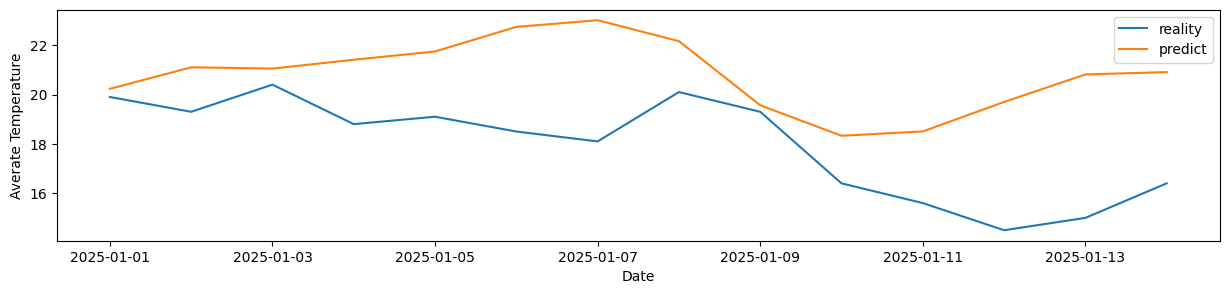

In [18]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,3))
ax.plot(weather_2025_df["date"], weather_2025_df["tavg"], label="reality")
ax.plot(predict_df_2025["date"], predict_df_2025["predicted_tavg"], label="predict")
ax.set_xlabel("Date")
ax.set_ylabel("Averate Temperature")
plt.legend()
plt.show()